# Backlash of the X or Y axis

Analysis of a run of `test_backlash.py`. Every photo of the run is one CSV row:
round, side (`below` = after the slow +STEP, `above` = after +APPROACH and back), commanded position, encoder count, photo.
The axis is in the file name (`backlash_x_...` / `backlash_y_...`).

Each round is a pair of photos at the same commanded position; only the two photos of a round are compared.

1. **image**: per round, shift of the `above` photo against the `below` photo (cross correlation)
2. **result**: backlash = that shift, from the image and from the encoder
3. **plot**: backlash per round

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# test_backlash.py writes to <repo>/encoder_test_data (not the encoder_test_data next to this notebook)
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".git").exists())
DATA_DIR = REPO / "encoder_test_data"
PLOT_DIR = DATA_DIR / "encoder_test_plots"   # the plots are saved here
PLOT_DIR.mkdir(exist_ok=True)

# the run: CSV of test_backlash.py, its photos are in <RUN>_photos
RUN = "backlash_x_20261015_153305"
CSV = DATA_DIR / f"{RUN}.csv"
PHOTO_DIR = DATA_DIR / f"{RUN}_photos"
IMAGE_CSV = DATA_DIR / f"{RUN}_image.csv"   # written by the image cell

UM_PER_PX = 0.1192      # pixel size on the calibration slide (10 um ruler period = 83.9 px)
# how the stage moves in the picture: "x" = left/right (X axis), "y" = up/down (Y axis);
# SIGN = +1 if + steps move the picture to +x / +y, -1 if the other way
PICTURE_DIR = "x"
SIGN = 1
UM_PER_STEP = 0.3125    # stage travel per motor step
UM_PER_COUNT = 1.95     # linear encoder, counts up for + steps

COLOR = "#eb6834"       # linear encoder, as the 24 h linear run

## 1. Image: backlash of every round

Per round, the shift of the `above` photo against the `below` photo of the same round: FFT cross
correlation of the windowed, high-passed images, the peak refined to sub-pixel with a parabola.
`image_um` is the shift along PICTURE_DIR in stage direction; `corr` is 1 for the same picture.
One row per round, written to `<RUN>_image.csv`.

In [2]:
photos = pd.read_csv(CSV, comment="#", usecols=["round", "side", "encoder", "photo"])
below = photos[photos.side == "below"].set_index("round")
above = photos[photos.side == "above"].set_index("round")

h, w = np.asarray(Image.open(PHOTO_DIR / below.photo.iloc[0]).convert("L")).shape
window = np.outer(np.hanning(h), np.hanning(w))
freq = np.hypot(np.fft.fftfreq(h)[:, None], np.fft.rfftfreq(w)[None, :])
highpass = freq >= 1 / 100   # drop the slow background (vignetting)

rows = []
for n in below.index:
    ref = np.asarray(Image.open(PHOTO_DIR / below.photo[n]).convert("L"), dtype=float)
    img = np.asarray(Image.open(PHOTO_DIR / above.photo[n]).convert("L"), dtype=float)
    A = np.fft.rfft2((ref - ref.mean()) * window) * highpass
    B = np.fft.rfft2((img - img.mean()) * window) * highpass
    a2 = (np.fft.irfft2(A, s=ref.shape) ** 2).sum()
    b2 = (np.fft.irfft2(B, s=ref.shape) ** 2).sum()
    cc = np.fft.irfft2(np.conj(A) * B, s=ref.shape)
    py, px = np.unravel_index(np.argmax(cc), cc.shape)
    c = cc[py, px]
    # parabola through the peak and its neighbours
    left, right = cc[py, px - 1], cc[py, (px + 1) % w]
    up, down = cc[py - 1, px], cc[(py + 1) % h, px]
    dx = px + 0.5 * (left - right) / (left - 2 * c + right)
    dy = py + 0.5 * (up - down) / (up - 2 * c + down)
    # a peak in the second half is a negative shift
    dx = dx - w if dx > w / 2 else dx
    dy = dy - h if dy > h / 2 else dy
    rows.append({"round": n, "dx_um": dx * UM_PER_PX, "dy_um": dy * UM_PER_PX,
                 "corr": c / np.sqrt(a2 * b2),
                 "encoder_below": below.encoder[n], "encoder_above": above.encoder[n]})

pairs = pd.DataFrame(rows)
pairs["image_um"] = SIGN * pairs[f"d{PICTURE_DIR}_um"]
pairs["encoder_um"] = (pairs.encoder_above - pairs.encoder_below) * UM_PER_COUNT   # empty for Y
pairs.to_csv(IMAGE_CSV, index=False)
pairs.round(3)

,round,dx_um,dy_um,corr,encoder_below,encoder_above,image_um,encoder_um
0,1,4.573,-0.025,0.783,38,41,4.573,5.85
1,2,3.313,-0.216,0.794,39,41,3.313,3.90
2,3,3.072,-0.044,0.795,38,41,3.072,5.85
3,4,5.709,-0.193,0.787,38,41,5.709,5.85
4,5,4.018,-0.052,0.785,39,40,4.018,1.95
5,6,2.818,-0.037,0.799,39,41,2.818,3.90
6,7,2.892,-0.038,0.797,40,40,2.892,0.00
7,8,2.709,-0.045,0.797,39,40,2.709,1.95
8,9,3.293,-0.047,0.791,39,41,3.293,3.90
9,10,3.026,-0.030,0.794,39,41,3.026,3.90


## 2. Result

backlash = position after `above` - position after `below`, per round
(positive = the stage stops short of the target). Mean and standard deviation over the rounds.

In [3]:
pairs = pd.read_csv(IMAGE_CSV, usecols=["round", "image_um", "encoder_um", "corr"])

image, encoder = pairs.image_um, pairs.encoder_um
print(f"backlash image   = {image.mean():+.2f} +- {image.std():.2f} um = {image.mean() / UM_PER_STEP:+.1f} steps")
print(f"backlash encoder = {encoder.mean():+.2f} +- {encoder.std():.2f} um = {encoder.mean() / UM_PER_STEP:+.1f} steps")
pairs.round(2)

backlash image   = +3.54 +- 0.96 um = +11.3 steps
backlash encoder = +3.70 +- 1.94 um = +11.9 steps


,round,corr,image_um,encoder_um
0,1,0.78,4.57,5.85
1,2,0.79,3.31,3.90
2,3,0.80,3.07,5.85
3,4,0.79,5.71,5.85
4,5,0.79,4.02,1.95
5,6,0.80,2.82,3.90
6,7,0.80,2.89,0.00
7,8,0.80,2.71,1.95
8,9,0.79,3.29,3.90
9,10,0.79,3.03,3.90


## 3. Plot

Backlash of every round: filled from the image, open from the encoder (steps of 1.95 um).

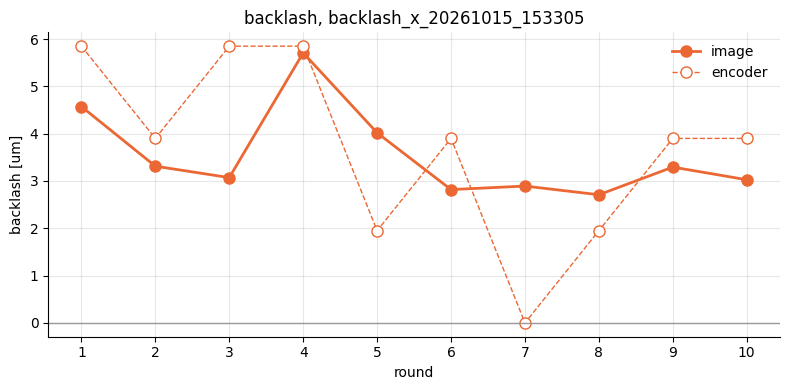

In [4]:
pairs = pd.read_csv(IMAGE_CSV, usecols=["round", "image_um", "encoder_um"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pairs["round"], pairs.image_um, "o-", color=COLOR, lw=2, ms=8, label="image")
ax.plot(pairs["round"], pairs.encoder_um, "o--", color=COLOR, lw=1, ms=8, mfc="white", label="encoder")
ax.axhline(0, color="0.6", lw=1)
ax.set_xlabel("round")
ax.set_ylabel("backlash [um]")
ax.set_xticks(pairs["round"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"backlash, {RUN}")
fig.tight_layout()
fig.savefig(PLOT_DIR / f"{RUN}.png", dpi=150)
plt.show()